In [2]:
pip install tensorflow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import tensorflow as tf
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras import layers,models
from tensorflow.keras.preprocessing import image

In [2]:
data = np.load('mnist_dataset.npz')
print(data.files)

['X_train', 'y_train', 'X_test', 'y_test']


In [3]:

with np.load('mnist_dataset.npz') as data:
    x_train, y_train = data['X_train'], data['y_train']
    x_test, y_test = data['X_test'], data['y_test']


In [4]:
x_train = np.expand_dims(x_train,axis=-1)
x_test = np.expand_dims(x_test,axis=-1)

In [5]:
x_train = np.repeat(x_train,3,axis=-1)
x_test = np.repeat(x_test,3,axis=-1)

In [6]:
x_train = tf.image.resize(x_train,(32,32))
x_test = tf.image.resize(x_test,(32,32))

In [7]:
x_train = x_train/255
x_test = x_test/255

In [8]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(32,32,3)
)

C:\Users\vedan\AppData\Local\Temp\ipykernel_16876\3182736805.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


In [9]:
base_model.trainable = False

In [10]:
model = models.Sequential([
 base_model,
 layers.GlobalAveragePooling2D(),
 layers.Dense(128,activation = "relu"),
  layers.Dense(10,activation = "softmax")
  ])

In [11]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"])

In [12]:
history = model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=3,batch_size=64,verbose=1)

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 101s 99ms/step - accuracy: 0.6228 - loss: 1.1473 - val_accuracy: 0.6746 - val_loss: 0.9502
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - accuracy: 0.6864 - loss: 0.9244 - val_accuracy: 0.6923 - val_loss: 0.9011
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 89ms/step - accuracy: 0.6992 - loss: 0.8815 - val_accuracy: 0.7036 - val_loss: 0.8671


313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step


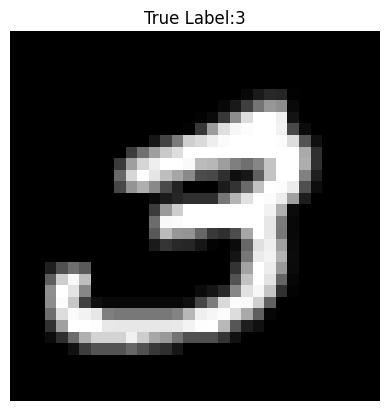

Prediction vector
 [1.3724381e-02 1.0053764e-07 1.9864237e-01 2.6540804e-01 6.8998059e-05
 3.2853298e-02 4.6739774e-03 3.0639116e-05 4.7428149e-01 1.0316735e-02]
Prediction vector Index
 8


In [21]:
p = model.predict(x_test)
r = random.randint(0,9999)

plt.imshow(x_test[r])
plt.axis("off")
plt.title(f"True Label:{y_test[r]}")
plt.show()

print("Prediction vector\n",p[r])

print("Prediction vector Index\n",np.argmax(p[r]))